# Week 6: Decision Trees, SVM, and Time-Series Analysis
**Assignments: 53, 54, 55**

Decision-tree classification, Support Vector Machines with different kernels, and time-series analysis with Pandas. The iris dataset is built into scikit-learn and the time-series data is generated in the notebook, so nothing needs to be downloaded.

## Required Libraries and Modules

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

## Assignment 53: Decision Tree Classification (Week 6, Day 4)
A decision tree splits the data with simple yes/no questions on the features.
We classify iris flowers into three species.

In [2]:
iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = iris.target

print(X.head())

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=1)

   sepal length (cm)  sepal width (cm)  petal length (cm)  petal width (cm)
0                5.1               3.5                1.4               0.2
1                4.9               3.0                1.4               0.2
2                4.7               3.2                1.3               0.2
3                4.6               3.1                1.5               0.2
4                5.0               3.6                1.4               0.2


In [3]:
# default tree (gini, no depth limit)
tree = DecisionTreeClassifier(random_state=1)
tree.fit(X_train, y_train)
print("Accuracy (default)          :", round(accuracy_score(y_test, tree.predict(X_test)), 3))

# a smaller tree using entropy and max depth 3 (easier to read, less overfitting)
tree_small = DecisionTreeClassifier(criterion="entropy", max_depth=3, random_state=1)
tree_small.fit(X_train, y_train)
print("Accuracy (entropy, depth 3) :", round(accuracy_score(y_test, tree_small.predict(X_test)), 3))

Accuracy (default)          : 0.956
Accuracy (entropy, depth 3) : 0.956


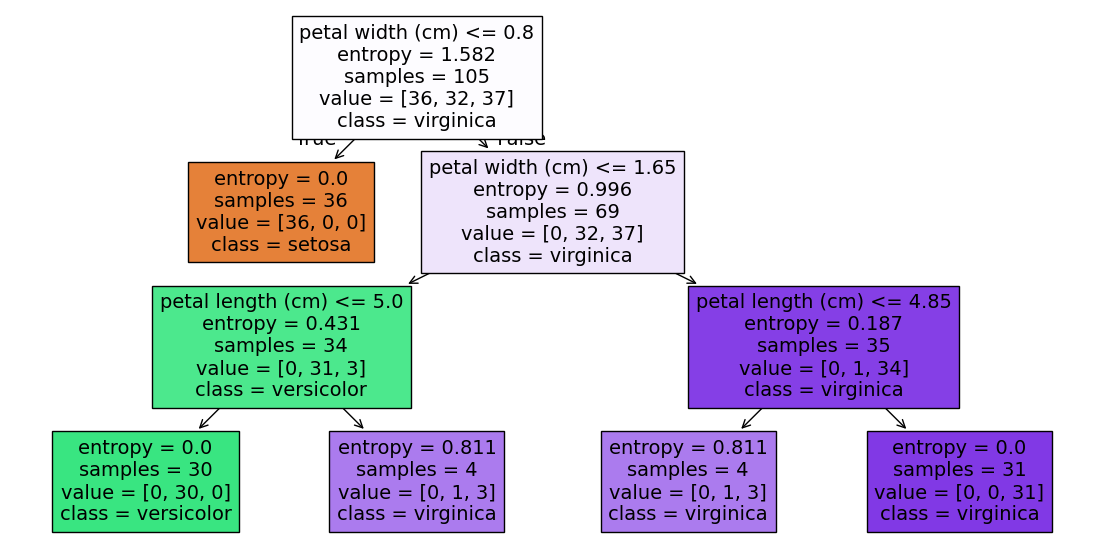

In [4]:
plt.figure(figsize=(14, 7))
plot_tree(tree_small, feature_names=iris.feature_names, class_names=iris.target_names, filled=True)
plt.show()

## Assignment 54: Support Vector Machines (SVM) (Week 6, Day 4)
An SVM finds the boundary that separates classes with the widest margin.
**Kernels** (polynomial, RBF, sigmoid) let it draw curved boundaries.

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    iris.data, iris.target, test_size=0.2, random_state=0
)

# SVMs work best on scaled features
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

for kernel in ["linear", "poly", "rbf", "sigmoid"]:
    svm = SVC(kernel=kernel, degree=3)
    svm.fit(X_train, y_train)
    accuracy = accuracy_score(y_test, svm.predict(X_test))
    print(f"{kernel:<8} kernel accuracy: {accuracy:.3f}")

linear   kernel accuracy: 1.000
poly     kernel accuracy: 0.900
rbf      kernel accuracy: 1.000
sigmoid  kernel accuracy: 0.867


In [6]:
svm_rbf = SVC(kernel="rbf")
svm_rbf.fit(X_train, y_train)
y_pred = svm_rbf.predict(X_test)

print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred, target_names=iris.target_names))

[[11  0  0]
 [ 0 13  0]
 [ 0  0  6]]
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        11
  versicolor       1.00      1.00      1.00        13
   virginica       1.00      1.00      1.00         6

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30



## Assignment 55: Time-Series Analysis with Pandas (Week 6, Day 5)
We build a daily electricity-consumption dataset (2015–2017) with weekly and yearly patterns, then:
indexing by date, plotting, seasonality, resampling, and rolling averages.

In [8]:
dates = pd.date_range("2015-01-01", "2017-12-31", freq="D")
day_of_year = dates.dayofyear.to_numpy()

rng = np.random.default_rng(0)
consumption = (
    1400
    + 150 * np.cos(2 * np.pi * day_of_year / 365)       # more in winter, less in summer
    - 200 * (dates.dayofweek >= 5)                       # less on weekends
    + rng.normal(0, 40, len(dates))                       # random noise
)

power = pd.DataFrame({"Consumption": consumption.round(1)}, index=dates)
power.index.name = "Date"

power["Year"] = power.index.year
power["Month"] = power.index.month
power["Weekday"] = power.index.day_name()

print(power.head())
print(power.shape)

            Consumption  Year  Month   Weekday
Date                                          
2015-01-01       1555.0  2015      1  Thursday
2015-01-02       1544.6  2015      1    Friday
2015-01-03       1375.4  2015      1  Saturday
2015-01-04       1353.8  2015      1    Sunday
2015-01-05       1528.0  2015      1    Monday
(1096, 4)


In [9]:
# select by date with loc
print(power.loc["2016-08-10"])
print(power.loc["2017-01-01":"2017-01-07", ["Consumption", "Weekday"]])

# partial-string indexing: all of February 2016
print("Rows in Feb 2016:", len(power.loc["2016-02"]))

Consumption       1302.0
Year                2016
Month                  8
Weekday        Wednesday
Name: 2016-08-10 00:00:00, dtype: object
            Consumption    Weekday
Date                              
2017-01-01       1322.6     Sunday
2017-01-02       1534.7     Monday
2017-01-03       1551.6    Tuesday
2017-01-04       1500.0  Wednesday
2017-01-05       1538.3   Thursday
2017-01-06       1490.6     Friday
2017-01-07       1326.2   Saturday
Rows in Feb 2016: 29


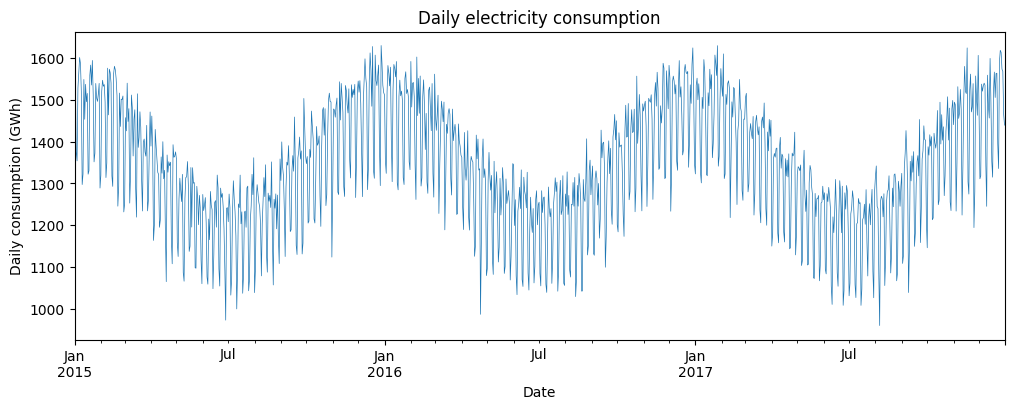

In [10]:
power["Consumption"].plot(figsize=(12, 4), linewidth=0.5)
plt.ylabel("Daily consumption (GWh)")
plt.title("Daily electricity consumption")
plt.show()

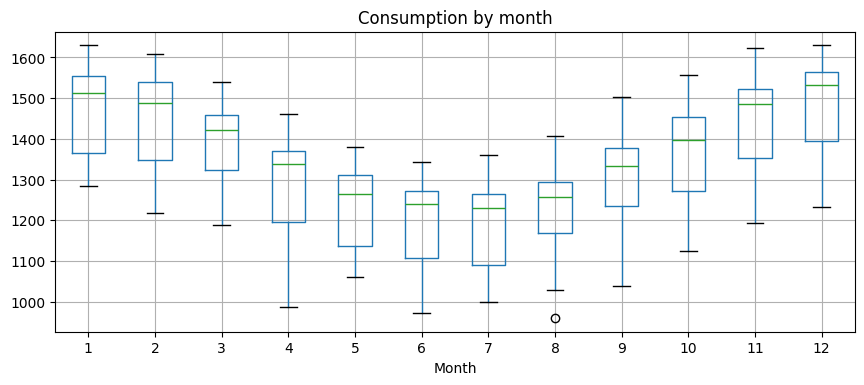

Weekday
Monday       1397.9
Tuesday      1395.6
Wednesday    1400.9
Thursday     1396.0
Friday       1399.9
Saturday     1198.6
Sunday       1199.7
Name: Consumption, dtype: float64


In [11]:
# seasonality: average consumption per month and per weekday
power.boxplot(column="Consumption", by="Month", figsize=(10, 4))
plt.suptitle("")
plt.title("Consumption by month")
plt.show()

weekday_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
print(power.groupby("Weekday")["Consumption"].mean().reindex(weekday_order).round(1))

Date
2015-01-04    1457.200000
2015-01-11    1488.428571
2015-01-18    1457.300000
2015-01-25    1500.900000
2015-02-01    1457.157143
Freq: W-SUN, Name: Consumption, dtype: float64


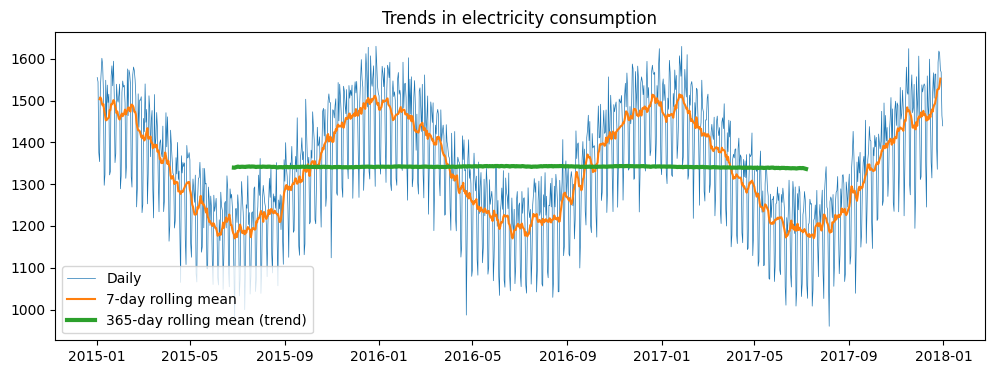

In [12]:
# resampling: daily -> weekly mean
weekly = power["Consumption"].resample("W").mean()
print(weekly.head())

# rolling windows: 7-day and 365-day averages show the trend
rolling_7d = power["Consumption"].rolling(7, center=True).mean()
rolling_365d = power["Consumption"].rolling(365, center=True, min_periods=360).mean()

plt.figure(figsize=(12, 4))
plt.plot(power["Consumption"], linewidth=0.5, label="Daily")
plt.plot(rolling_7d, label="7-day rolling mean")
plt.plot(rolling_365d, linewidth=3, label="365-day rolling mean (trend)")
plt.legend()
plt.title("Trends in electricity consumption")
plt.show()